# 01. Jupyter & Google Colab で始める Drawlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuichi110/drawlib/blob/main/docs/jupyter/ja/01_quickstart_colab.ipynb)

インタラクティブな **Drawlib ハンズオンノートブック** シリーズへようこそ！Drawlib の `type = "jupyter"` プロジェクトは、解説テキスト（Markdown）・構成図（`drawlib` ブロック）・実行可能な Python セルを単一の Markdown ソースとして統合管理します。

![Drawlib による図解付き Jupyter ノートブック & Google Colab ワークフロー](https://www.drawlib.com/jupyter/images/01_quickstart_colab/01_hero_colab_workflow.png)

*Drawlib による図解付き Jupyter ノートブック & Google Colab ワークフロー*

---

## 1. `setup(..., cwd=True)` による決定的なパス解決

通常の `.py` スクリプトでは、Drawlib はスクリプトファイルが存在するディレクトリを基準に相対パス（`save()`、`image()`、`Dimage()` など）を解決します。一方、**JupyterLab** や **Google Colab**、あるいはインプロセスのドライラン実行では物理的な `.py` ファイルが存在しないため、`setup(..., cwd=True)` を明示的に指定することでカレントワーキングディレクトリ（`os.getcwd()`）を基準に決定的なパス解決を行います。

In [ ]:
!pip install -q drawlib

In [1]:
import os
from drawlib.canvas import clear, setup

setup(width=100, height=30, cwd=True)
print(f"Canvas initialized in working directory: {os.path.basename(os.getcwd())}")
clear()

Canvas initialized in working directory: jupyter


---

## 2. `show()` によるインライン図解レンダリング

ノートブック内では、前のセルで定義した変数が後続のセルへそのまま引き継がれます。Python セルでサービス一覧を定義し、次のセルで図解としてインライン描画してみましょう。

In [2]:
services = [
    ("Edge Gateway", "TLS 1.3 / Envoy", 18.0),
    ("Auth Service", "OAuth2 / JWT", 50.0),
    ("Core Engine", "Python 3.12", 82.0),
]
print(f"Loaded {len(services)} architecture nodes for inline rendering.")
services[-1]

Loaded 3 architecture nodes for inline rendering.


('Core Engine', 'Python 3.12', 82.0)

定義した `services` 変数を Drawlib キャンバス上に描画します。

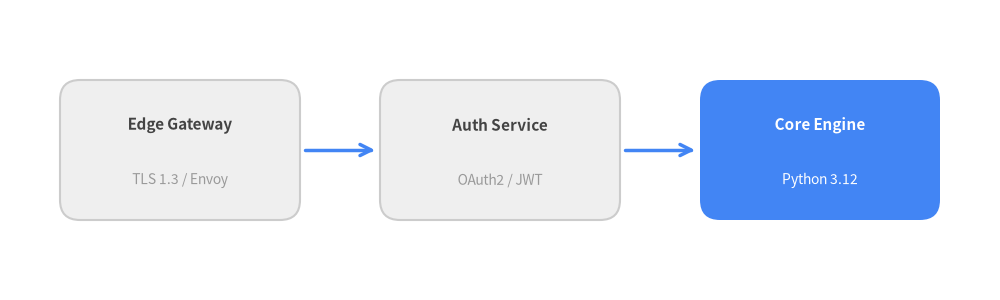

In [3]:
from drawlib.canvas import show, setup
from drawlib.lines import line
from drawlib.shapes import rectangle
from drawlib.styles import Styles
from drawlib.text import text

setup(width=100, height=30, cwd=True)

for idx, (name, stack, cx) in enumerate(services):
    box_style = Styles.PrimaryFlat if idx == 2 else Styles.Neutral
    title_style = Styles.WhiteBold if idx == 2 else Styles.DarkBold
    sub_style = Styles.White if idx == 2 else Styles.Muted

    rectangle((cx, 15), width=24, height=14, style=box_style.patch(shape_r=2.0))
    text((cx, 17.5), name, style=title_style.patch(text_size=11))
    text((cx, 12.0), stack, style=sub_style.patch(text_size=10))

line((30.5, 15), (37.5, 15), arrow_head="->", style=Styles.PrimaryBold)
line((62.5, 15), (69.5, 15), arrow_head="->", style=Styles.PrimaryBold)

show()